In [2]:
import io
import os
import json
import zipfile
import gzip
from datetime import date
import pandas as pd
import requests
from dotenv import load_dotenv
load_dotenv()  # Charge les variables du fichier .env dans l'environnement

token = os.getenv("SPECIESPLUS_TOKEN")

In [3]:
url = "https://api.speciesplus.net/"
endpoint='/api/v1/downloads'
headers = {
    "X-Authentication-Token": token,
    "Accept": "application/json",
}
params = {
    # "name": "Mammalia",
}
response = requests.get(url + endpoint, headers=headers, params=params, timeout=30)
response.raise_for_status()
data = response.json()
# print(data)
url_download=data[0]['download_url']
# print(url_download)
response = requests.get(url_download, timeout=60)
response.raise_for_status()   # arrête tout si le téléchargement a échoué      

In [20]:
# The keys whose value is a list → each one becomes its own table
LIST_KEYS = ["synonyms", "accepted_names", "common_names", "cites_listings", "cites_quotas",
             "cites_suspensions", "eu_listings", "eu_decisions", "distributions", "references"]

# One empty list per table, stored in a dict
tables = {"tb_taxon_concepts": []}
for key in LIST_KEYS:
    tables[f"tb_{key}"] = []
# tables

In [21]:

with gzip.open(io.BytesIO(response.content), "rt", encoding="utf-8") as f:
    for line in f:
        taxon = json.loads(line)
        taxon_concept_id=taxon.get('id')
        # num_tags=0
        # if taxon_concept_id!=3023:
        #     continue
        for keys in tables.keys():
            name=keys.removeprefix("tb_")
            to_add=taxon.pop(name, None)
            if to_add:
                for dict in to_add:
                    dict["taxon_concept_id"]=taxon_concept_id
                    # num_tags=len(dict["tags"])
                tables[keys].extend(to_add)
        tables["tb_taxon_concepts"].extend([taxon])
        # if num_tags>0:
        #     print(taxon_concept_id)
        #     break
            # if num_keys_avail>6:
            #     print(taxon_concept_id)
            #     break
        

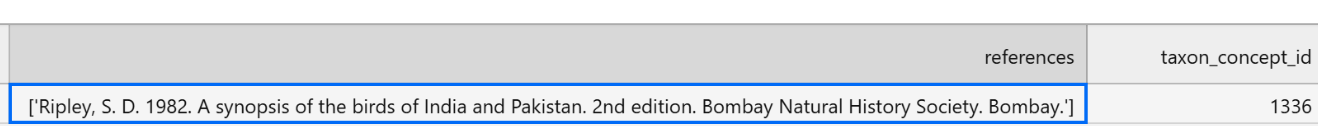
Inside distributions there is a variabel called "references" and "tags" with a list of strings inside. check what to do with it, leave value as list or make another table? "id": 1336

In [22]:

pd.json_normalize(tables["tb_distributions"], sep="_").head()

,id,iso_code2,name,tags,type,references,taxon_concept_id
0,32243,MG,Madagascar,[],COUNTRY,"[Olivieri, G., Zimmermann, E., Randrianambinin...",795
1,19302,MG,Madagascar,[],COUNTRY,"[Kappeler, P. M., Rasoloarison, R. M., Razafim...",1037
2,15388,IN,India,[],COUNTRY,"[Ripley, S. D. 1982. A synopsis of the birds o...",1336
3,72435,MG,Madagascar,[],COUNTRY,"[Thalmann, U. and Geissmann, T. 2005. New spec...",1446
4,15179,MG,Madagascar,[],COUNTRY,"[Andriaholinirina, N., Fausser, J.-L., Roos, C...",2239


In [24]:
for keys in tables.keys():
    df = pd.json_normalize(tables[keys], sep="_")
    df.to_csv(keys+'.csv', index=False)